# Explicabilidad del modelo y análisis de interacciones

Los valores SHAP permiten estudiar las contribuciones predictivas del modelo seleccionado. Se presentan importancia global, gráficos de dependencia y dos casos individuales correctamente clasificados. El análisis se complementa con interacciones TreeSHAP de XGBoost, identificadas como resultados de ese modelo.

In [1]:
from pathlib import Path
import os,sys,json,subprocess,time
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
assert (ROOT/'src/run_analysis.py').exists(), 'Abra el notebook dentro del proyecto'
os.environ['MPLCONFIGDIR']=str(ROOT/'tmp/matplotlib')
os.environ['XDG_CACHE_HOME']=str(ROOT/'tmp/cache')
sys.path.insert(0,str(ROOT/'src'))
def run_script(name,*args):
    started=time.perf_counter()
    result=subprocess.run([sys.executable,str(ROOT/'src'/name),*map(str,args)],cwd=ROOT,text=True,capture_output=True)
    (ROOT/'reports').mkdir(exist_ok=True)
    (ROOT/'reports'/f'notebook_{name}_{Path(str(args[-1])).name if args else "run"}.log').write_text(result.stdout+result.stderr)
    print(result.stdout[-4500:].replace(str(ROOT),'${PROJECT_ROOT}').replace(str(Path.home()),'${HOME}'))
    if result.returncode: print(result.stderr); result.check_returncode()
    print(f'Ejecución real completada en {time.perf_counter()-started:.1f} segundos')
def show(name): display(Image(filename=str(ROOT/'reports/figures'/name)))
def table(name): display(pd.read_csv(ROOT/'reports/tables'/name).head(20))
def results(): return json.loads((ROOT/'reports/results.json').read_text())
print('Python:',sys.version.split()[0], '| kernel del entorno del proyecto')


Python: 3.12.14 | kernel del entorno del proyecto


## Contribuciones globales y casos individuales

SHAP explica el score anterior a la calibración. Su referencia, unidades y muestra de explicación se documentan junto a los resultados. Las contribuciones se diferencian de la probabilidad calibrada y de cualquier efecto causal. Los casos individuales representan extremos correctamente clasificados y se presentan sin identificadores personales.

Cohorte y particiones 13105 3439
Completado shap CatBoost

Ejecución real completada en 4.1 segundos
Ganador: CatBoost | unidades: log-odds
Residuo aditividad: 6.217248937900877e-15


,variable,mean_abs_shap
0,edad,1.088106
1,log_gasto_pc,0.414796
2,prop_publicas,0.253314
3,lengua_materna,0.144055
4,electricidad,0.141076
5,log_ingreso_pc,0.117604
6,rural,0.093104
7,internet_hogar,0.090203
8,altitud,0.080881
9,ratio_alumnos_docente,0.049307


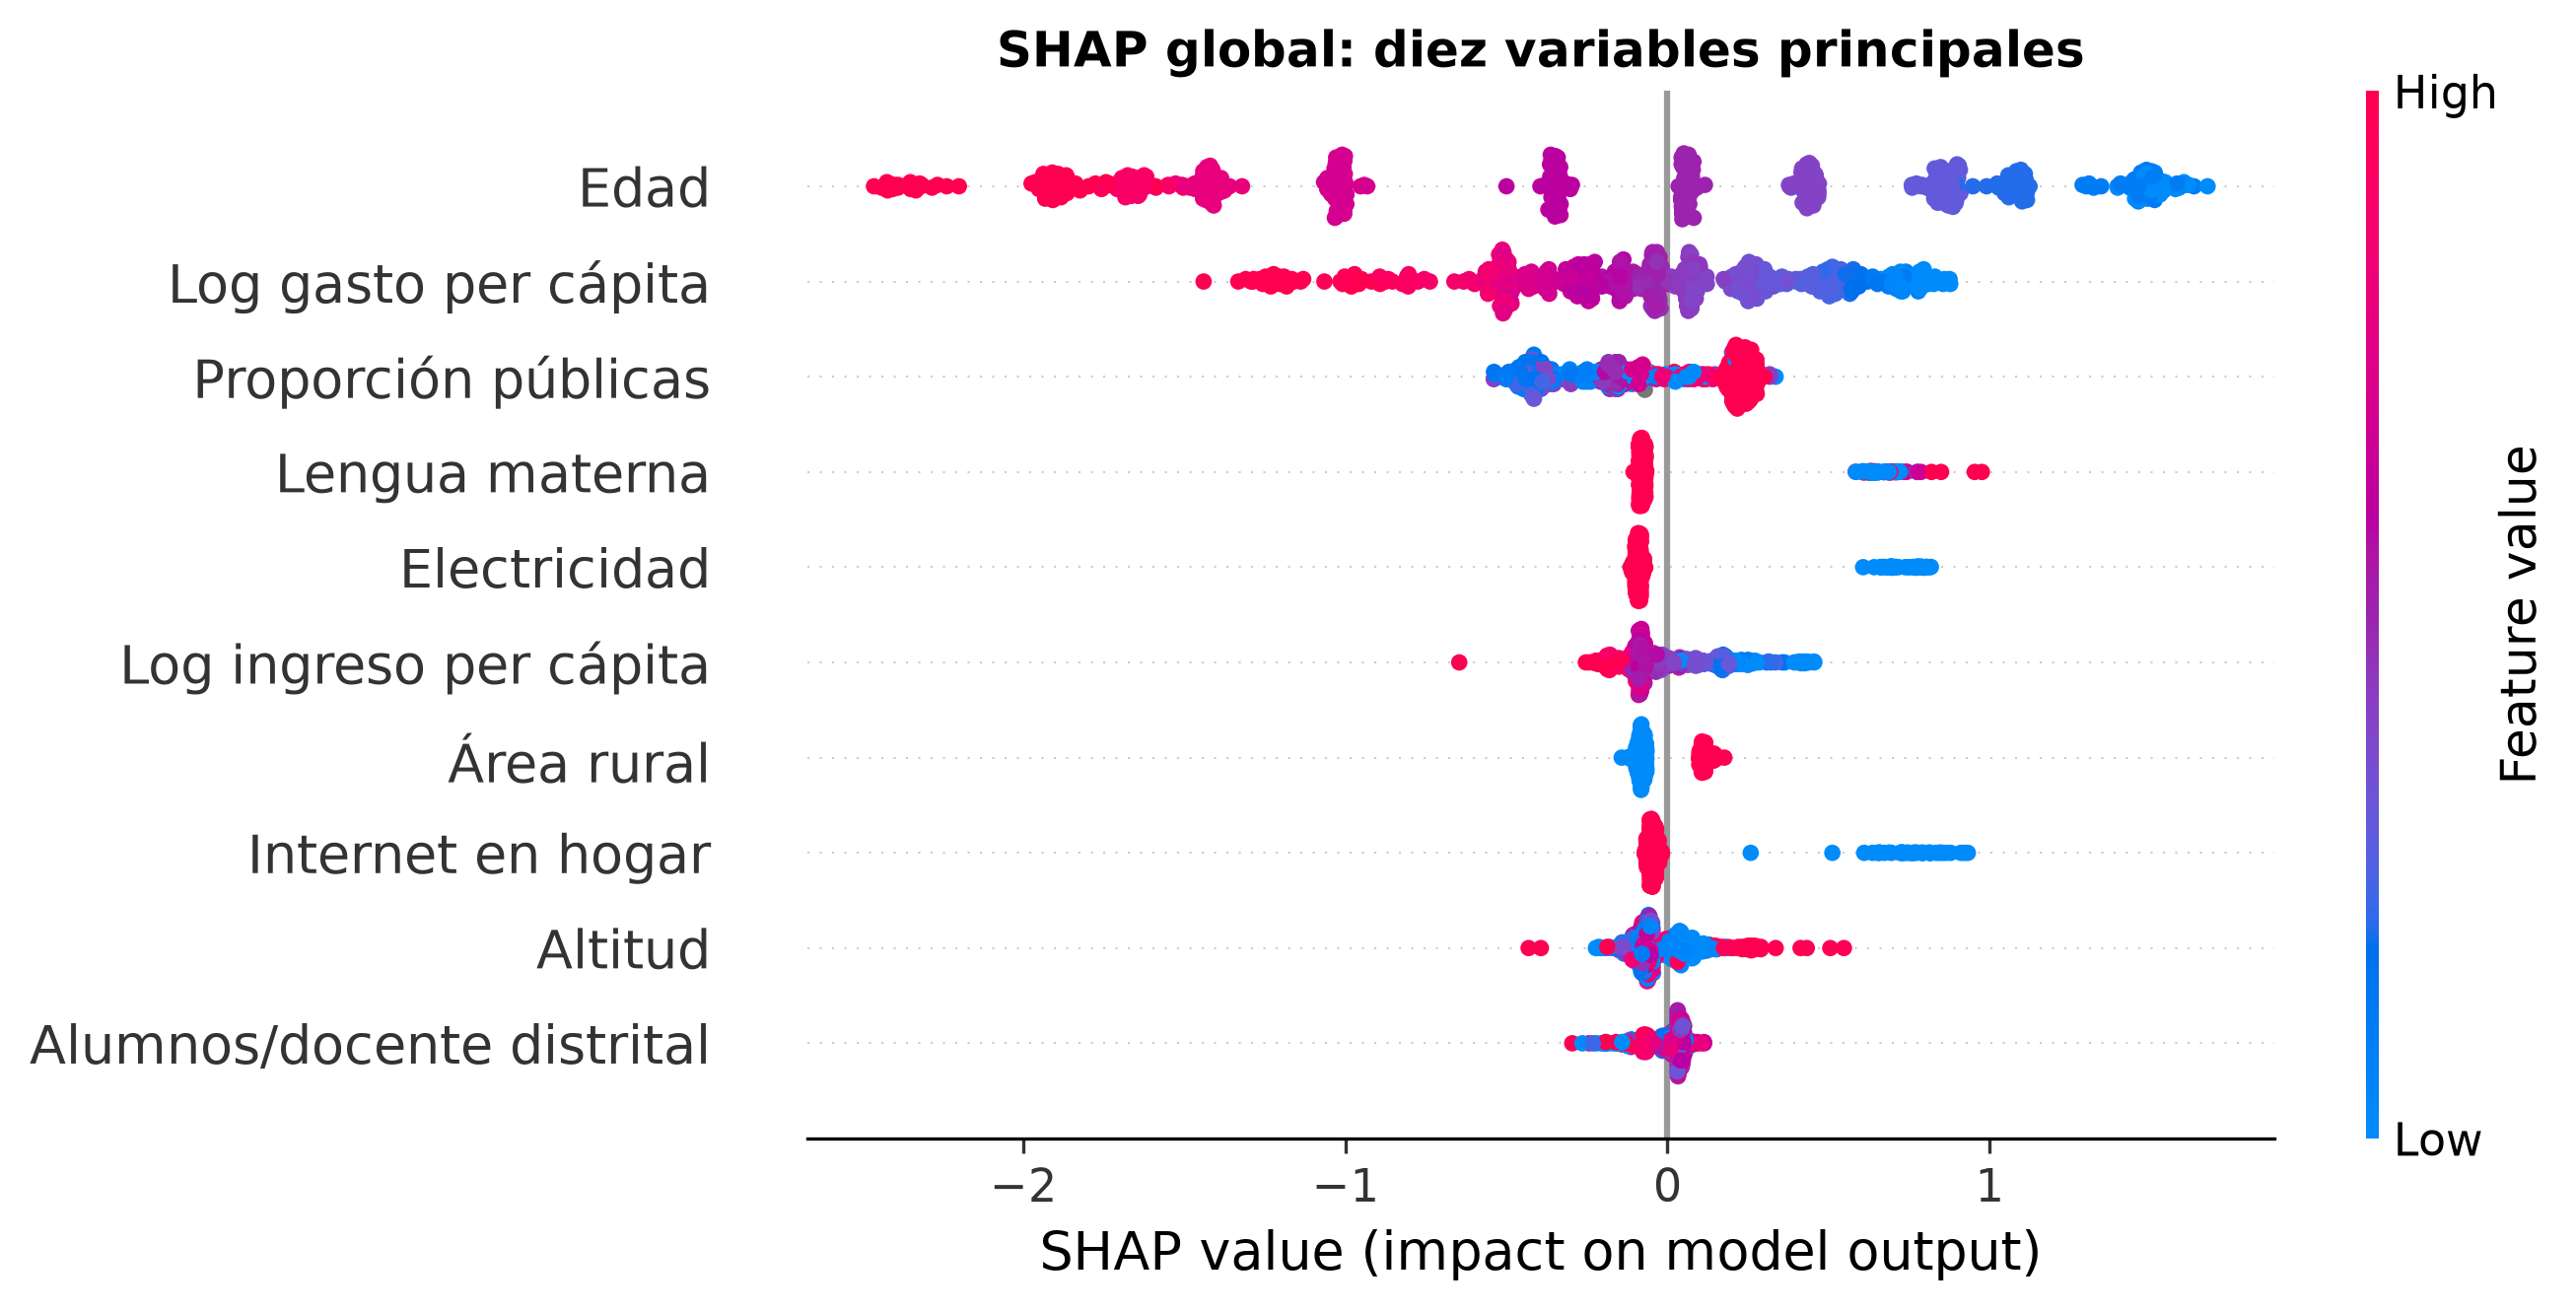

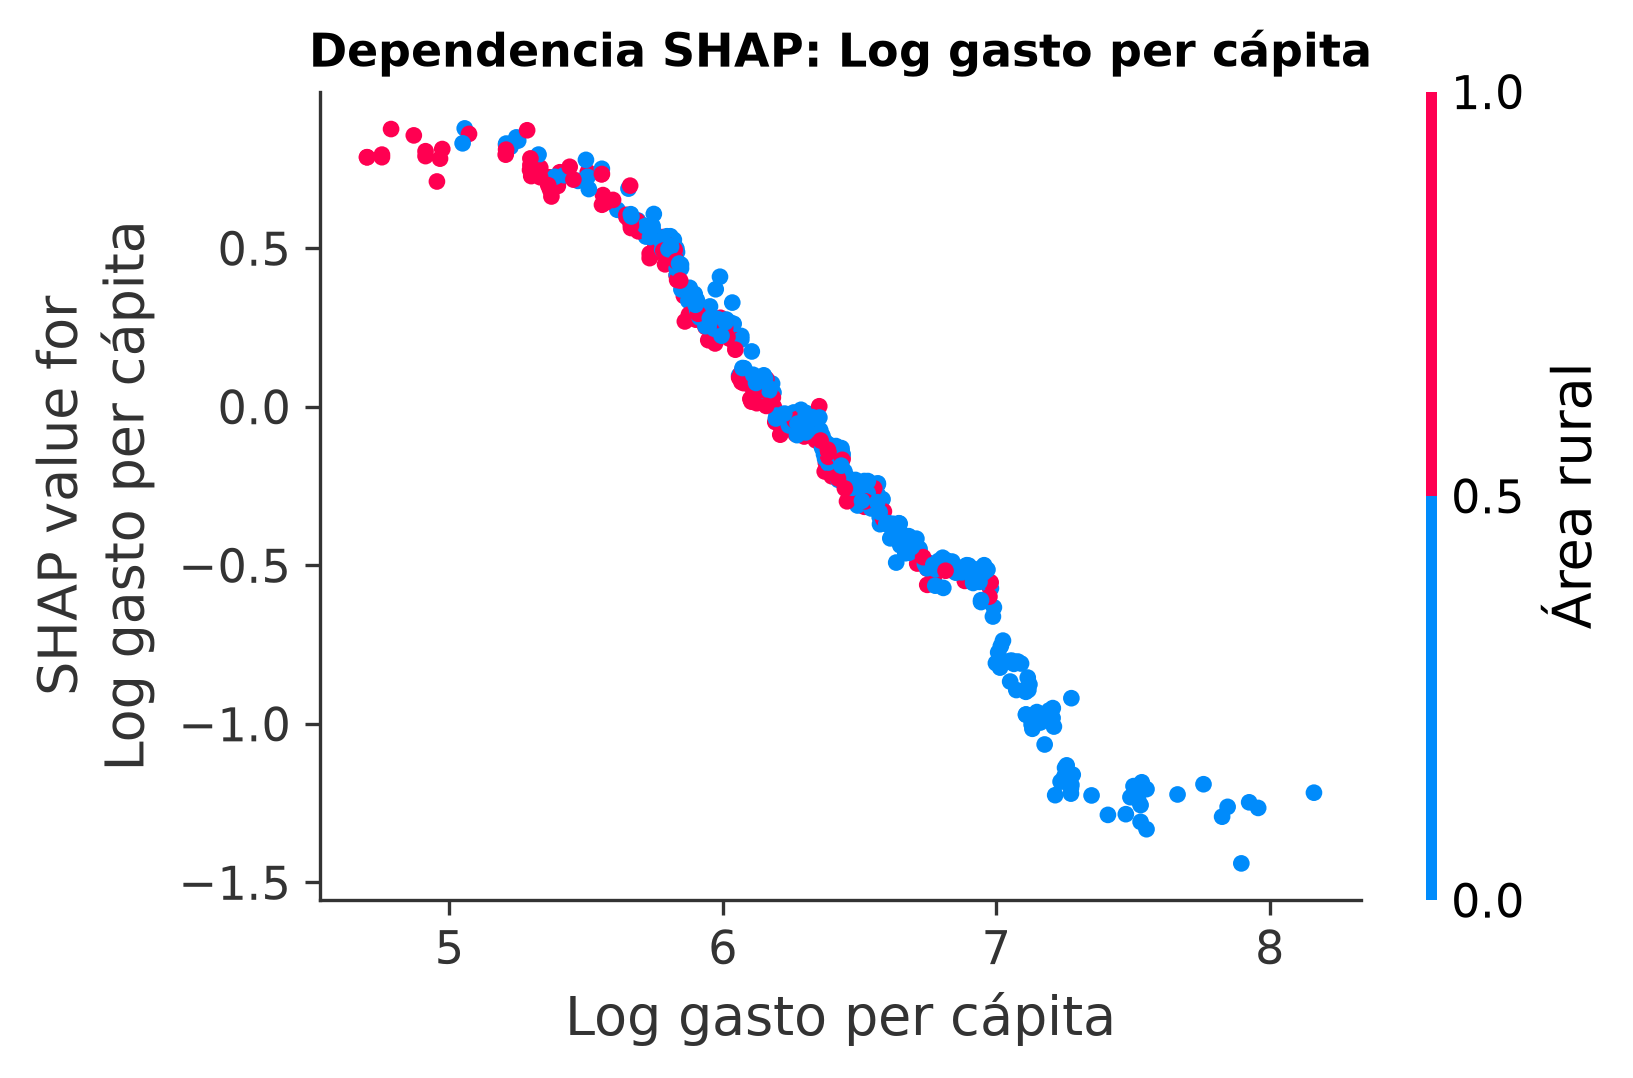

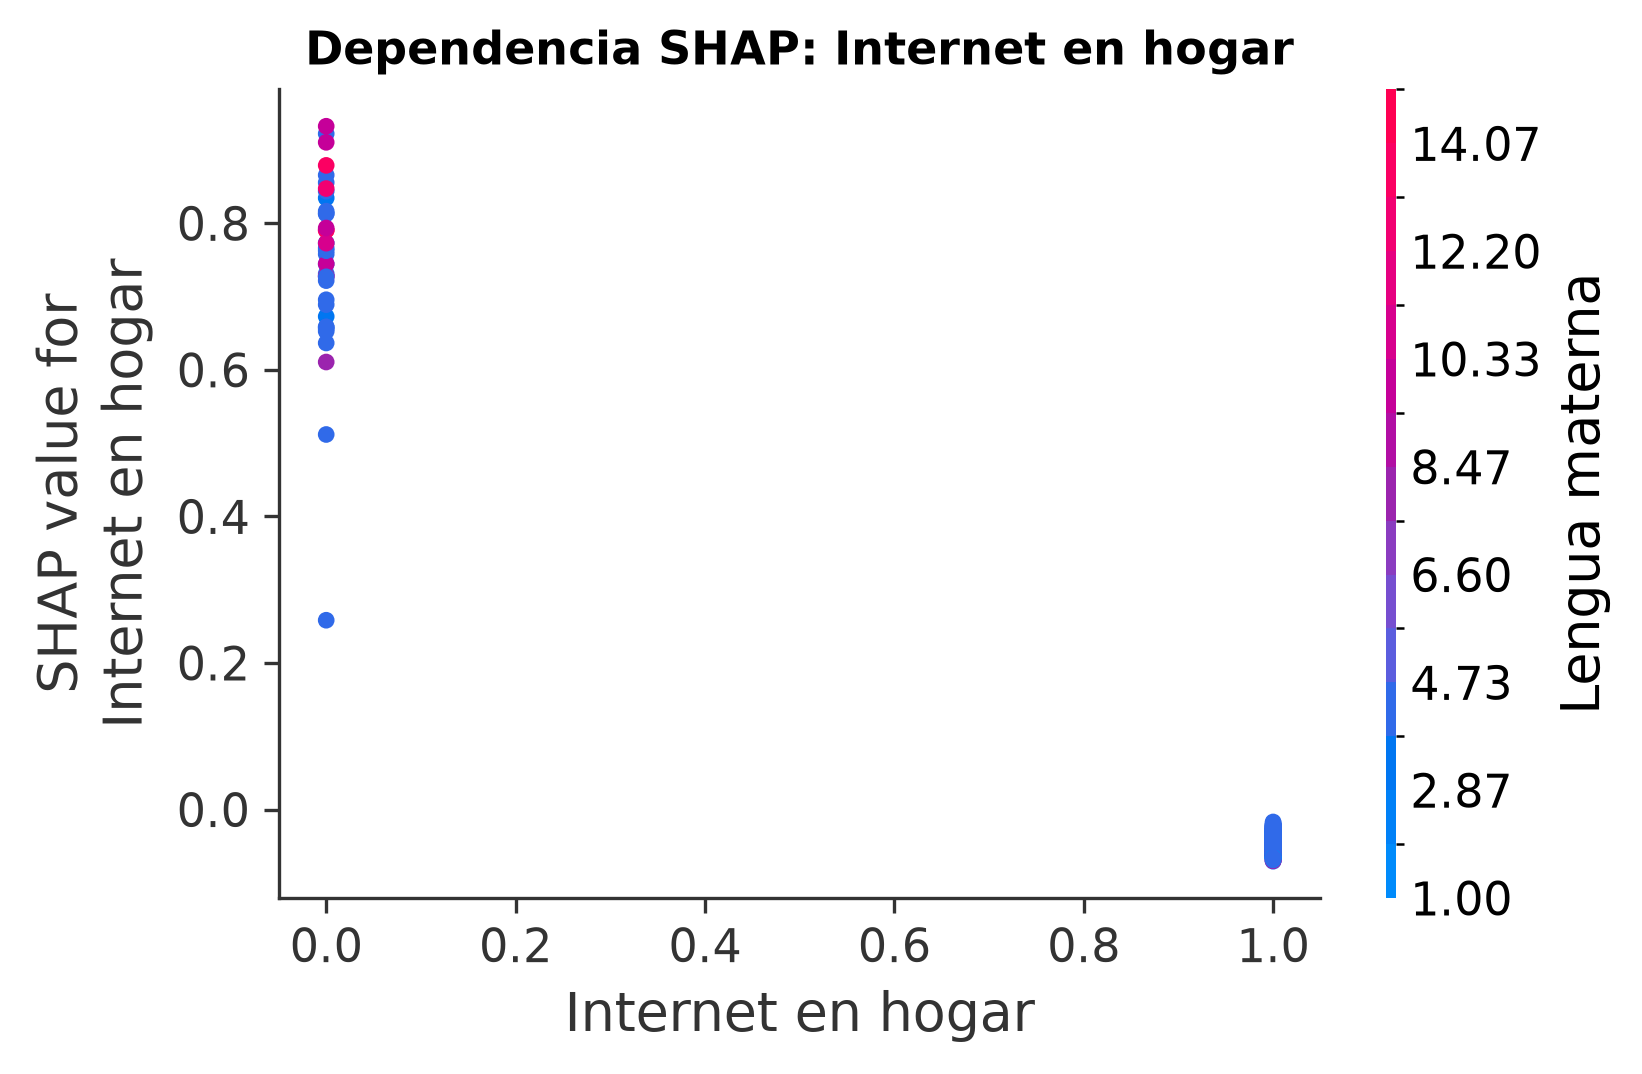

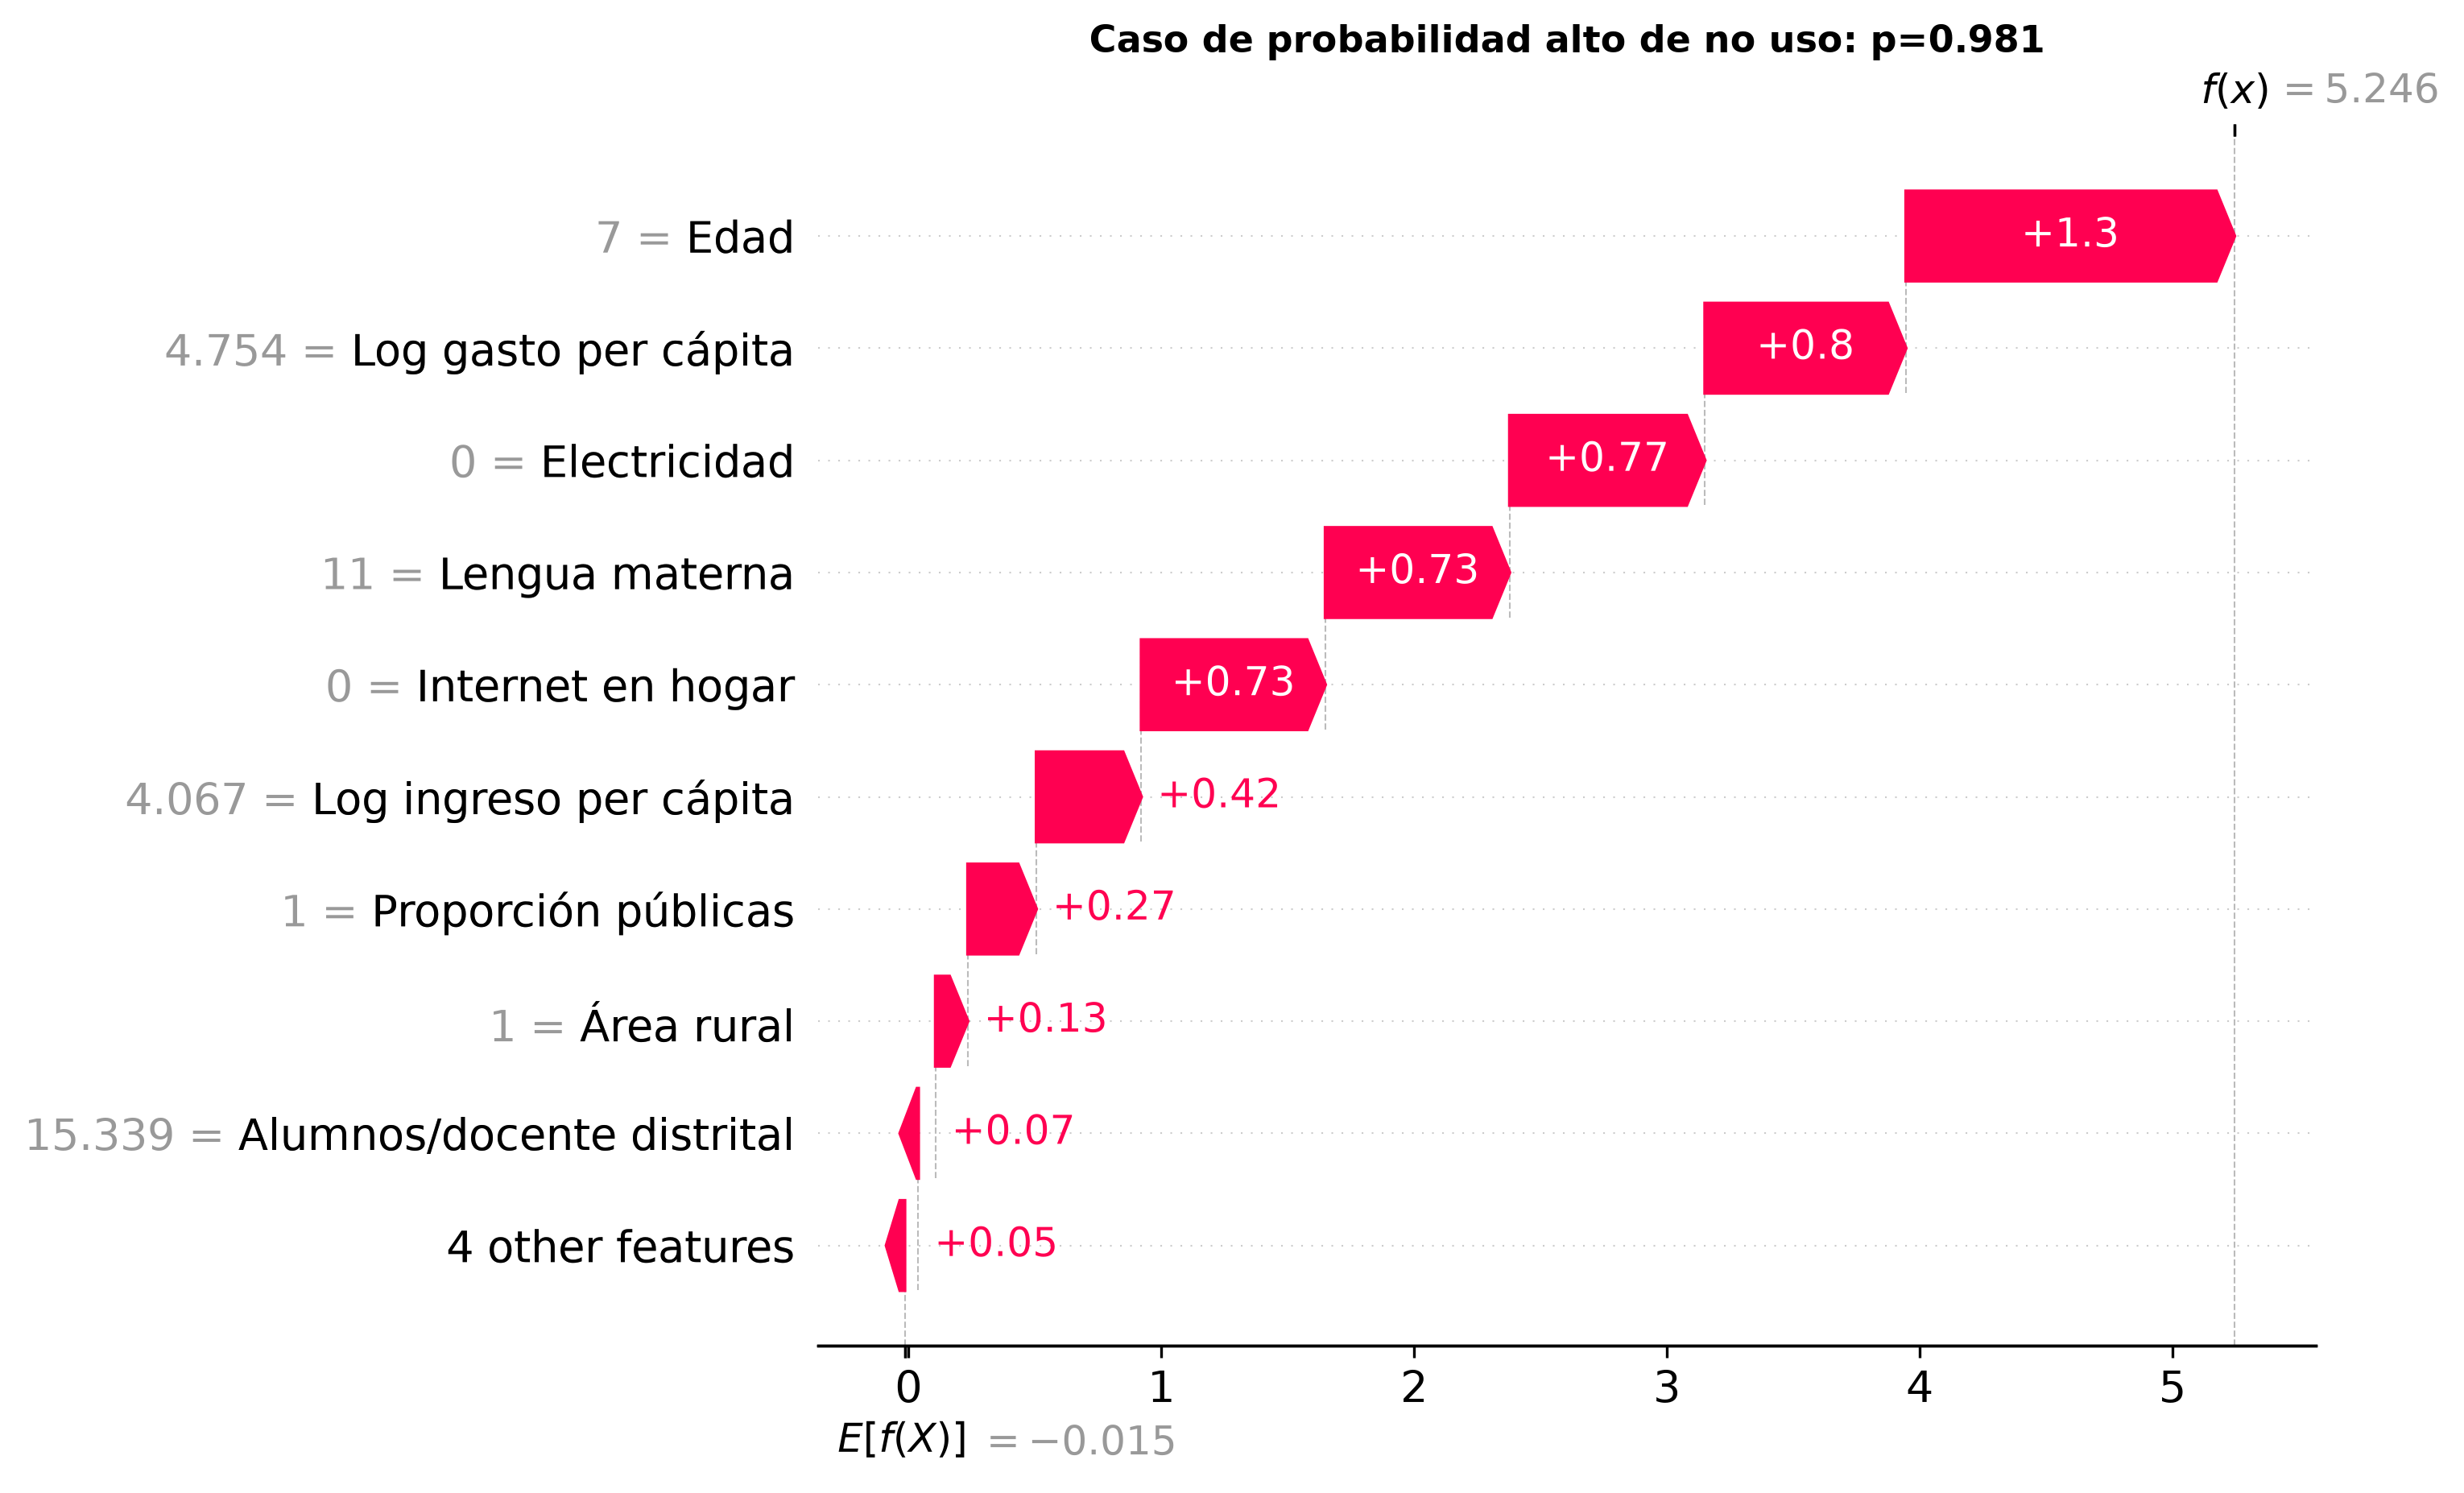

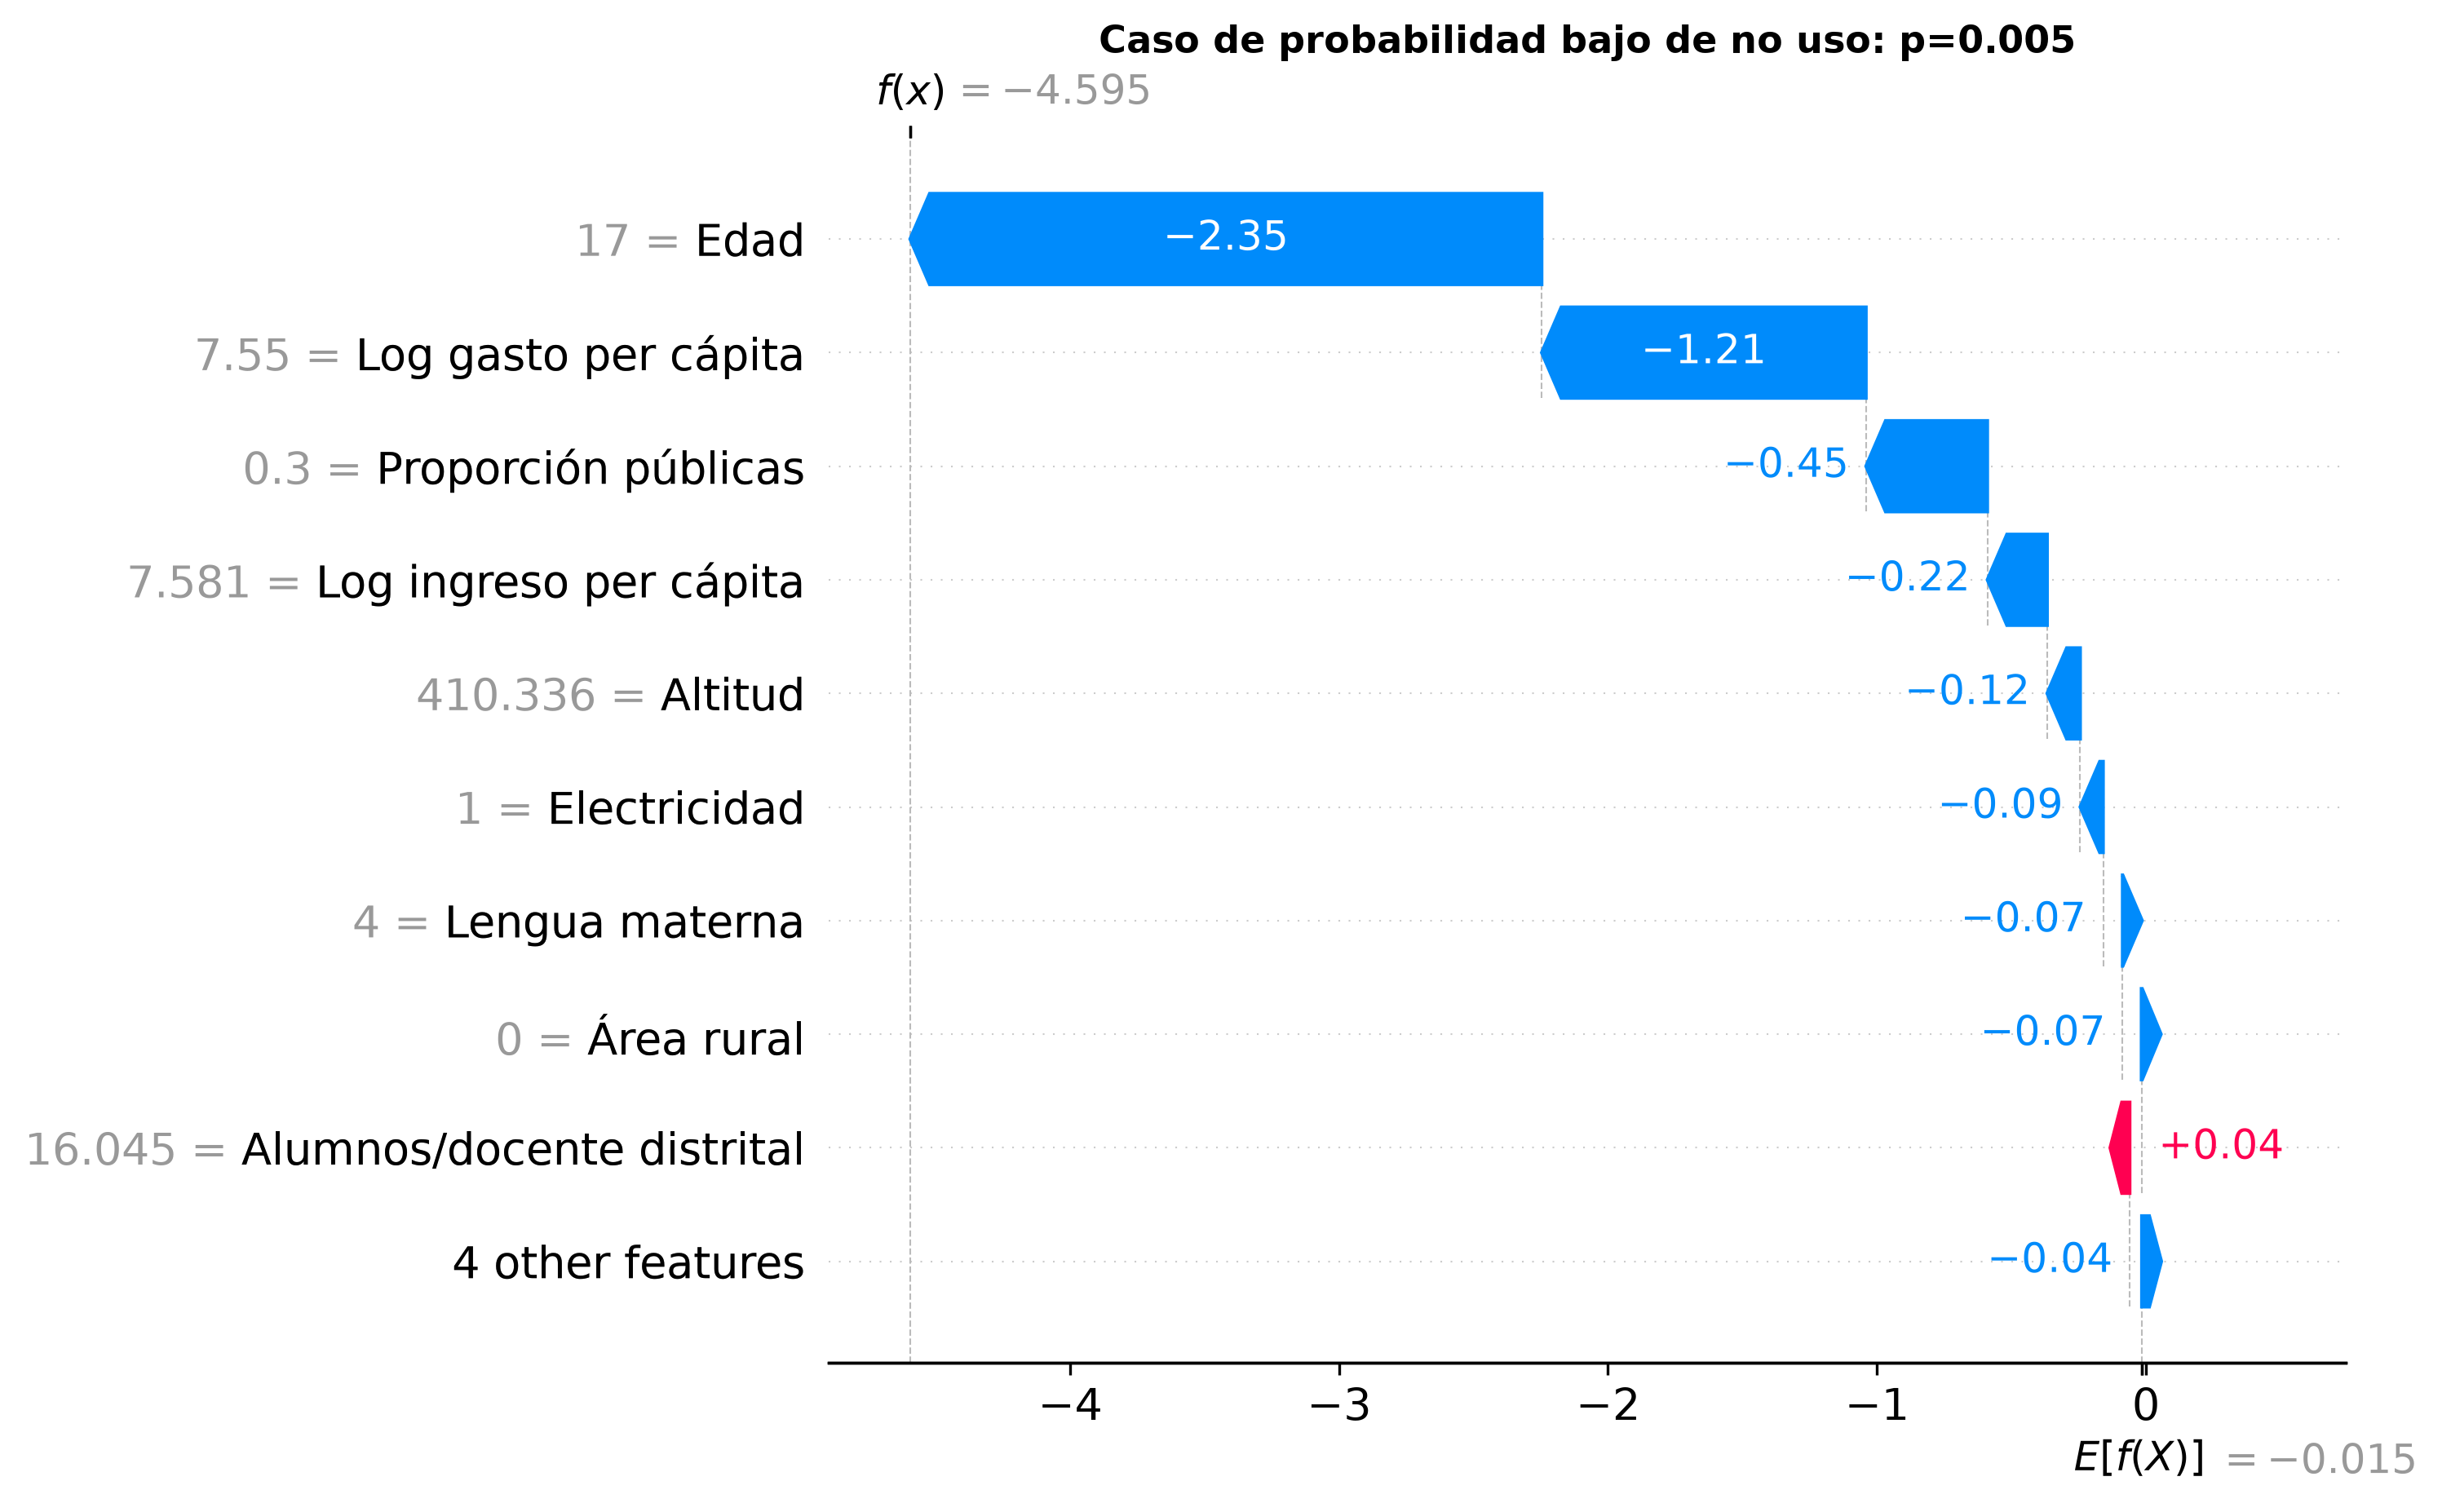

In [2]:
run_script('run_analysis.py','--phase','shap')
r=results()
print('Ganador:',r['supervised']['winner'],'| unidades:',r['shap']['units'])
print('Residuo aditividad:',r['shap']['max_additivity_residual'])
table('shap_importance.csv')
for name in ['shap_beeswarm.png','shap_dependence_1.png','shap_dependence_2.png','shap_waterfall_alto.png','shap_waterfall_bajo.png']: show(name)

## Interacciones predictivas del modelo de árboles

Los valores de interacción TreeSHAP cuantifican la contribución conjunta de pares de variables al score; el aporte del par se expresa como 2φᵢⱼ. Los pares se seleccionan de forma exploratoria por su contribución absoluta media. El color de un gráfico de dependencia, por sí solo, no demuestra una interacción ni su significación estadística.

{'model': 'XGBoost', 'winner': 'CatBoost', 'role': 'Análisis complementario; no sustituye al ganador', 'n_explained': 180, 'sample_seed': 42, 'units': 'log-odds antes de calibrar', 'background': 'TreeSHAP tree_path_dependent: cobertura de hojas ajustada en desarrollo', 'max_additivity_residual': 2.6226043701171875e-06, 'max_interaction_row_residual': 1.430511474609375e-06, 'note': 'El par aporta 2*phi_ij al score; las interacciones son propiedades predictivas del árbol ajustado, no efectos causales ni pruebas de significación. La selección de pares es exploratoria posterior al ajuste.'}


,variable_1,variable_2,mean_abs_pair_contribution
0,internet_hogar,log_gasto_pc,0.016388
1,log_gasto_pc,prop_publicas,0.015970
2,altitud,ratio_alumnos_docente,0.012402
3,rural,internet_hogar,0.010581
4,lengua_materna,altitud,0.009753
5,rural,log_gasto_pc,0.006630
6,log_ingreso_pc,log_gasto_pc,0.006579
7,lengua_materna,log_gasto_pc,0.005633
8,altitud,log_gasto_pc,0.005528
9,internet_hogar,prop_publicas,0.005317


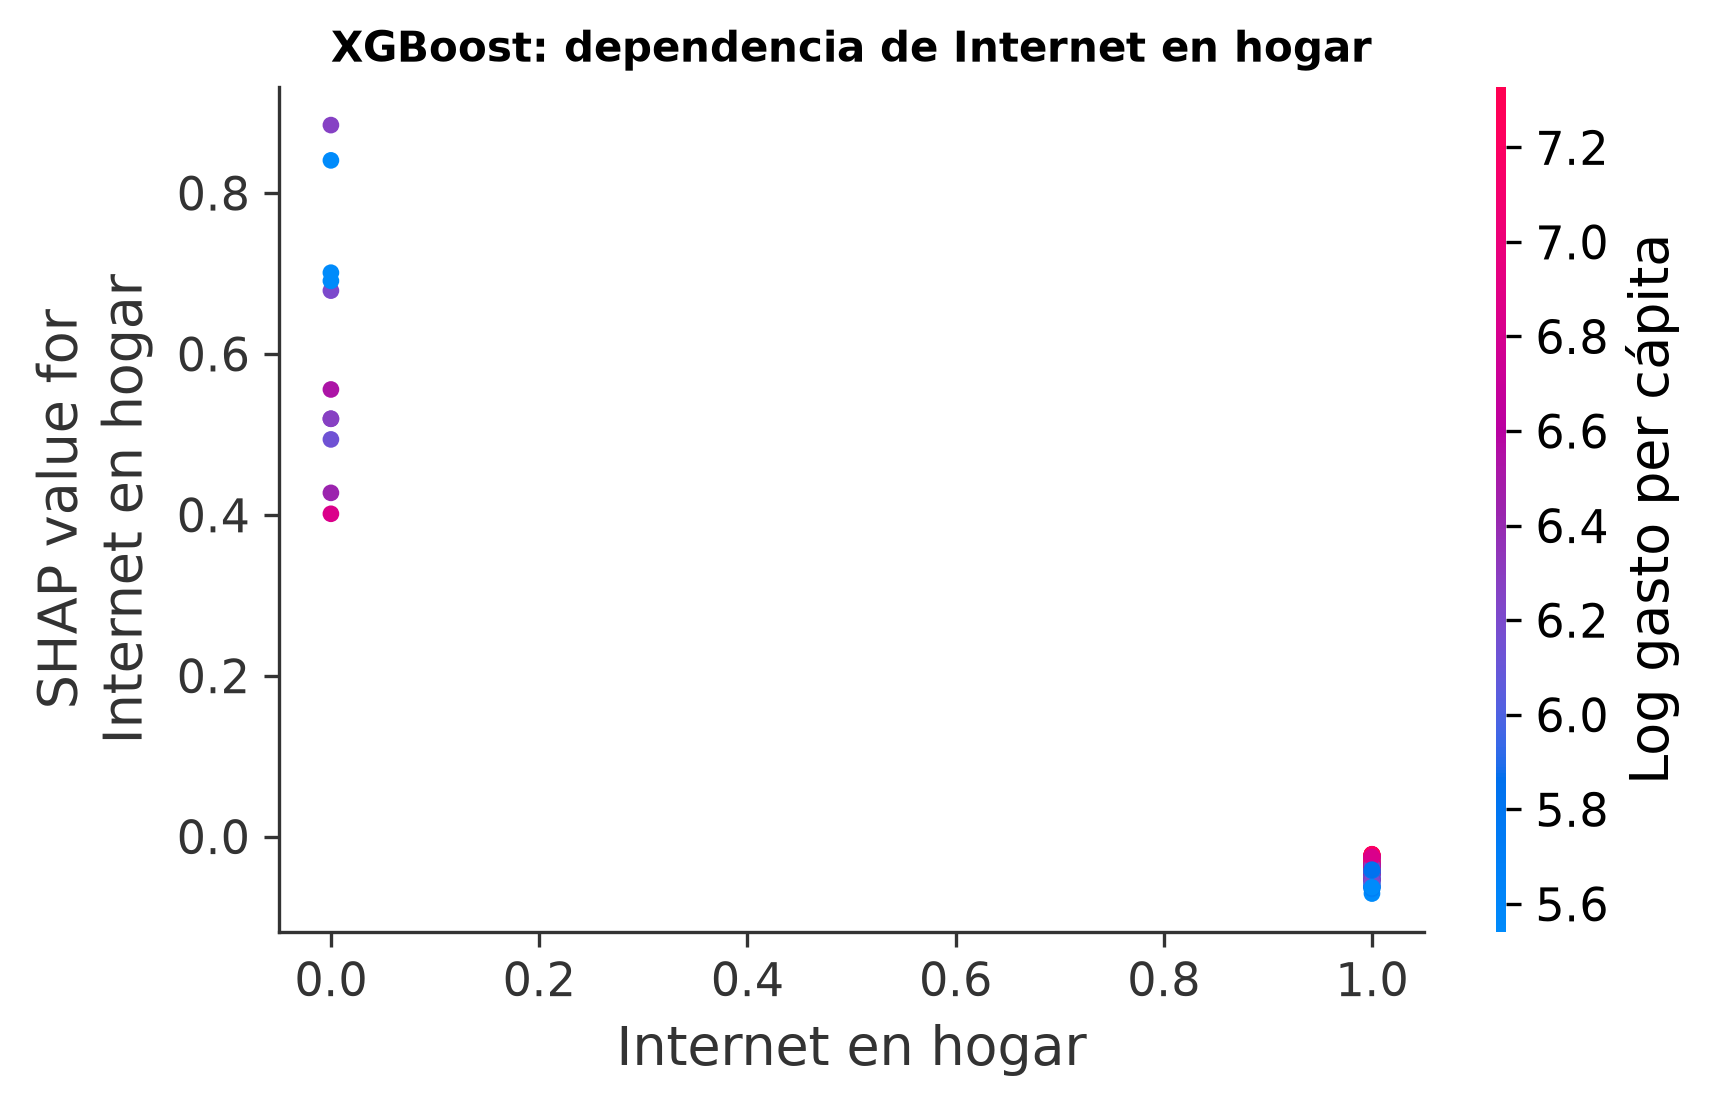

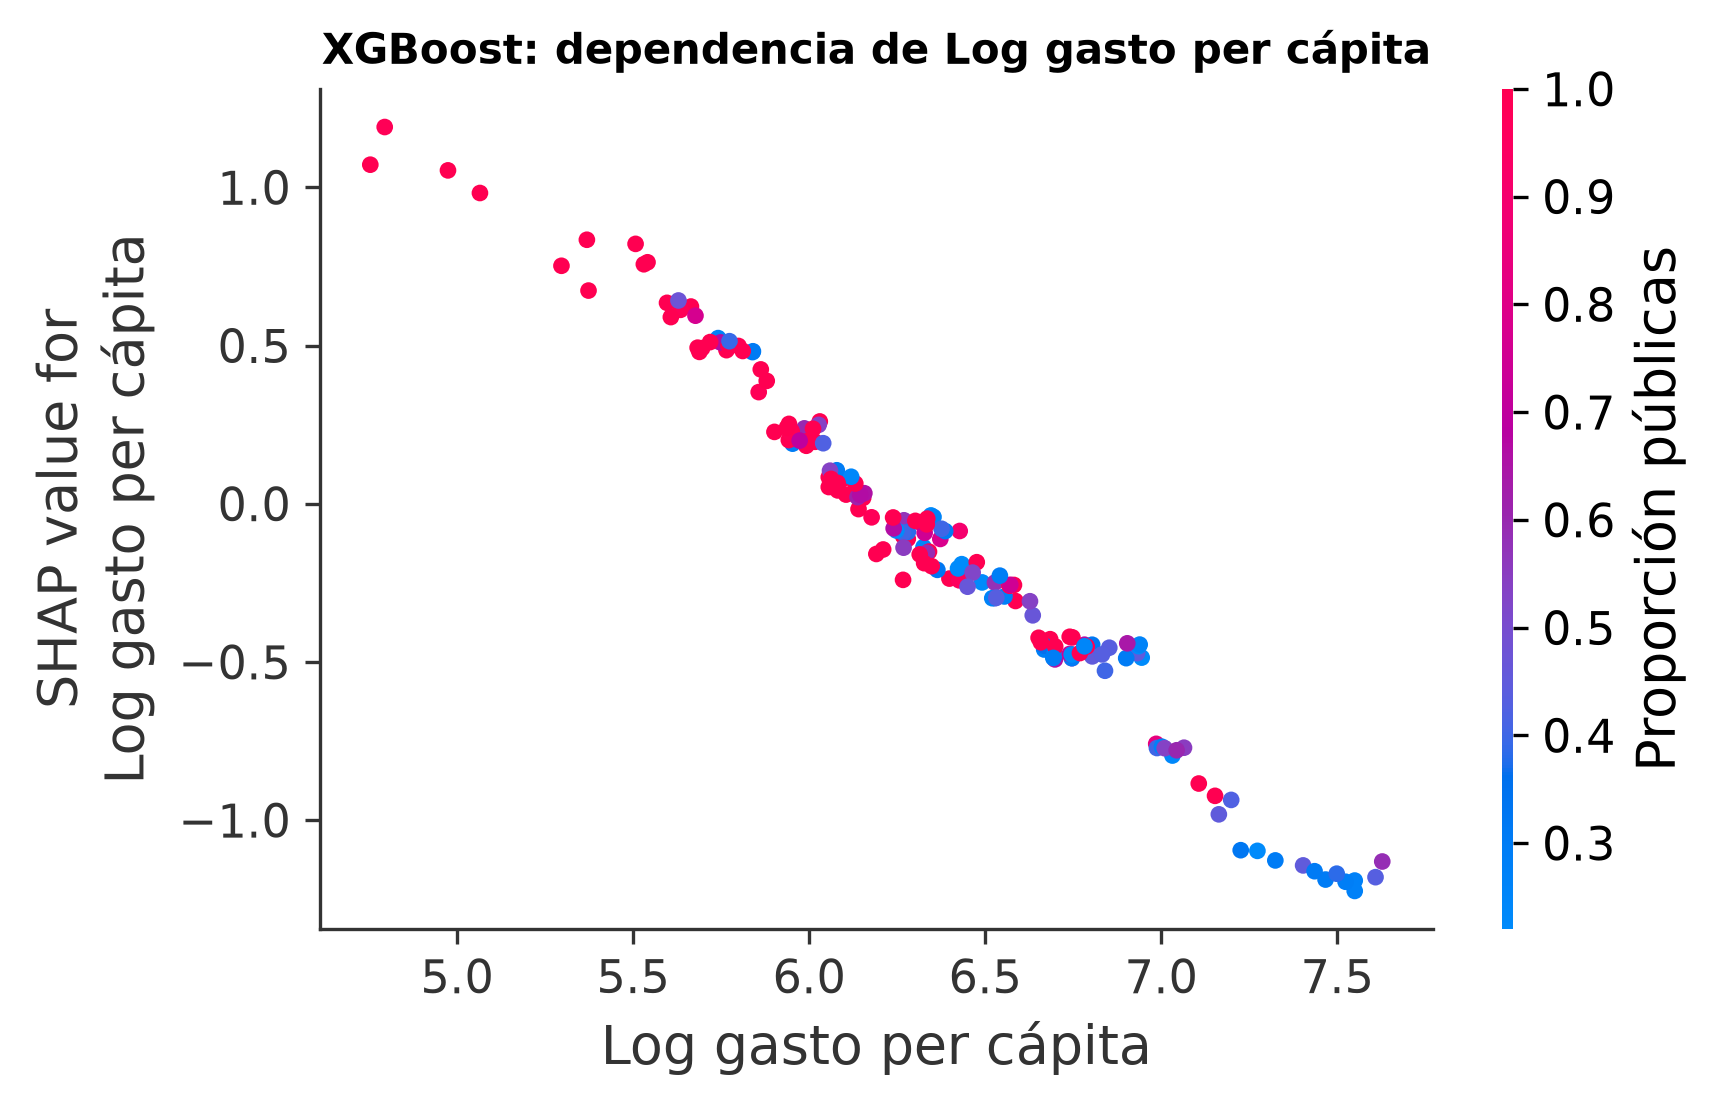

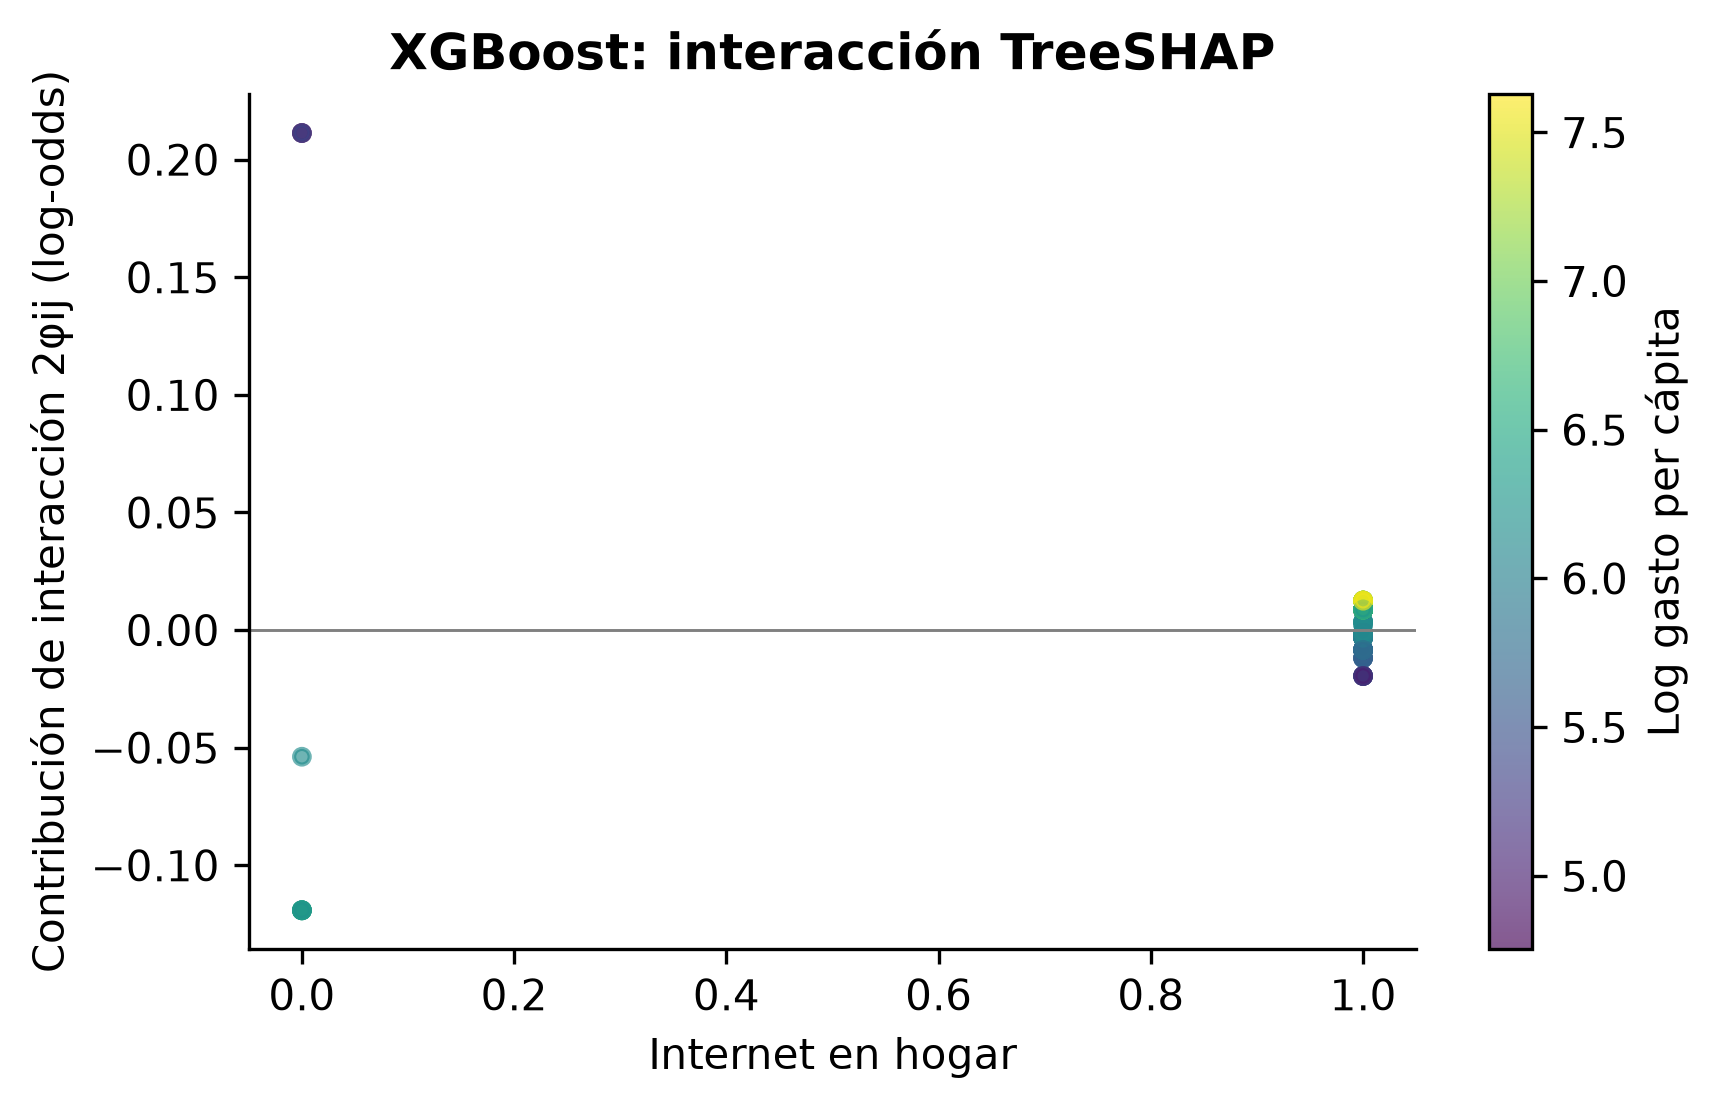

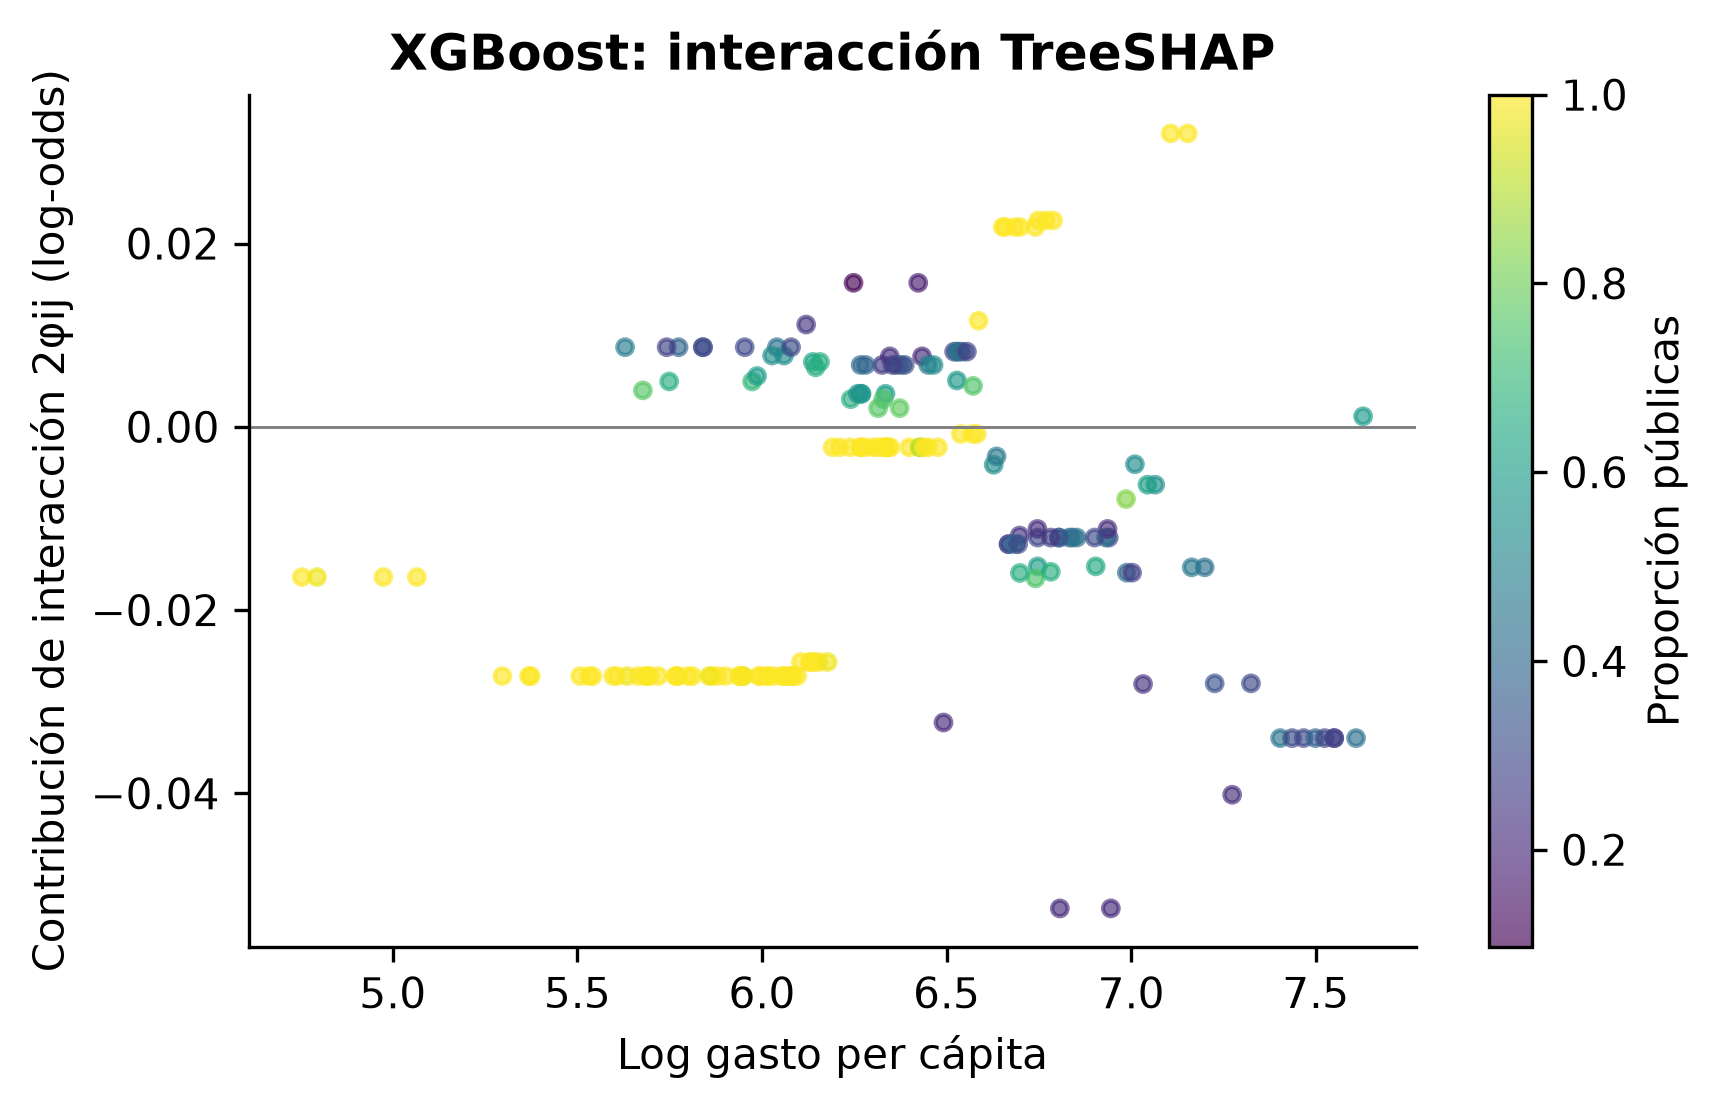

In [3]:
print({k:v for k,v in r['nonlinear_shap'].items() if k!='pairs'})
table('shap_interactions_xgboost.csv')
for name in ['shap_nonlinear_dependence_1.png','shap_nonlinear_dependence_2.png','shap_interaction_1.png','shap_interaction_2.png']: show(name)

## Interpretación y limitaciones de la explicabilidad

Las contribuciones permiten describir cómo utiliza el modelo las condiciones individuales, del hogar y del contexto territorial. No identifican mecanismos causales ni diagnostican habilidades digitales. Los casos extremos ilustran el comportamiento del clasificador y no representan a toda la población de estudio. Las recomendaciones requieren contraste y validación en campo.